# Bài tập nâng cao - Bước 3: Sai phân thường + mùa vụ
**Dataset 2:** AirPassengers (số hành khách hàng không theo tháng, 1949-01 đến 1960-12, 144 quan sát, chu kỳ mùa vụ s = 12)

**Mục tiêu:** tìm số lần sai phân thường **d** và sai phân mùa **D** để chuỗi trở nên **dừng**, chuẩn bị cho bước 4 (ACF/PACF) và mô hình SARIMA.

## 1. Thư viện
- `numpy`, `pandas`: xử lý dữ liệu và chuỗi thời gian.
- `matplotlib`: vẽ đồ thị.
- `adfuller` (statsmodels): kiểm định ADF để xem chuỗi dừng hay chưa.

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

## 2. Hiểu hai loại sai phân bằng ví dụ nhỏ

- **Sai phân thường** `diff()`: lấy giá trị **trừ giá trị tháng trước**. Dùng để **bỏ xu hướng** (chuỗi tăng dần).
- **Sai phân mùa** `diff(12)`: lấy giá trị **trừ giá trị cùng tháng năm trước** (cách 12 bước). Dùng để **bỏ mùa vụ** (mẫu lặp lại mỗi năm).

Ví dụ thu nhỏ bên dưới có mẫu mùa lặp mỗi **4 bước** (thay cho 12) và tăng thêm 2 sau mỗi chu kỳ.

In [27]:
mau = pd.Series([10, 20, 30, 20,     # chu kỳ 1
                 12, 22, 32, 22,     # chu kỳ 2 (mỗi giá trị cao hơn 2)
                 14, 24, 34, 24])    # chu kỳ 3

print("Chuỗi ban đầu       :", mau.tolist())
print("Sai phân mùa (s=4)  :", mau.diff(4).dropna().tolist(), "-> mẫu mùa biến mất, chỉ còn mức tăng không đổi")
print("Thêm sai phân thường:", mau.diff(4).diff().dropna().tolist(), "-> hết cả xu hướng, còn toàn số 0")

Chuỗi ban đầu       : [10, 20, 30, 20, 12, 22, 32, 22, 14, 24, 34, 24]
Sai phân mùa (s=4)  : [2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0] -> mẫu mùa biến mất, chỉ còn mức tăng không đổi
Thêm sai phân thường: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0] -> hết cả xu hướng, còn toàn số 0


**Thử đổi số:** đổi mức tăng sau mỗi chu kỳ (từ 2 thành 5), hoặc đổi mẫu mùa, rồi chạy lại để thấy sai phân mùa luôn loại được mẫu lặp. Với AirPassengers, mẫu lặp mỗi **12 tháng** nên dùng `diff(12)`.

## 3. Đọc dữ liệu

- **Vì sao đổi cột ngày thành index thời gian?** Để pandas hiểu đây là chuỗi thời gian (thứ tự và khoảng cách giữa các điểm có ý nghĩa), từ đó mới dùng được `diff()`, `rolling()` và vẽ theo trục thời gian.
- `asfreq("MS")` khai báo dữ liệu theo tháng (ngày đầu mỗi tháng).
- `iloc[:, 0]` lấy cột đầu tiên, nên không phụ thuộc tên cột.
- **Lưu ý link:** link AirPassengers trong đề (`airlinepassengers.csv`) bị lỗi 404. File vẫn còn với tên có gạch ngang `airline-passengers.csv`.

In [28]:
URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
df = pd.read_csv(URL, parse_dates=[0], index_col=0)
print(df.columns.tolist())              # kỳ vọng: ['Passengers']
ap = df.iloc[:, 0].asfreq("MS")
print(len(ap), ap.index.min().date(), ap.index.max().date())   # kỳ vọng: 144 điểm, 1949-01 đến 1960-12

['Passengers']
144 1949-01-01 1960-12-01


## 4. Hàm kiểm định ADF

- **H₀:** chuỗi **có nghiệm đơn vị**, tức **không dừng**. **H₁:** chuỗi dừng.
- **p-value ≤ 0.05** → bác bỏ H₀ → chuỗi **dừng**. **p-value > 0.05** → chưa đủ bằng chứng → chuỗi **chưa dừng**.
- `regression="c"`: mô hình kiểm định có hằng số. `autolag="AIC"`: tự chọn số độ trễ phù hợp.
- `result_object=False`: giữ cách trả về cũ và tránh cảnh báo `FutureWarning` của thư viện.

In [29]:
def adf_report(x, name):
    x = x.dropna()
    stat, p, *_ = adfuller(x, regression="c", autolag="AIC", result_object=False)
    print(f"{name:<40} ADF = {stat:8.4f} | p = {p:.4f} | {'DỪNG' if p <= 0.05 else 'KHÔNG DỪNG'}")
    return p

## 5. Tạo các bản sai phân và kiểm định ADF

| Biến | Cách tạo | Tác dụng |
|---|---|---|
| `d1` | `ap.diff()` | Sai phân thường (d = 1): bỏ xu hướng |
| `s12` | `ap.diff(12)` | Sai phân mùa (D = 1, s = 12): bỏ mùa vụ |
| `d1_s12` | `ap.diff().diff(12)` | Cả hai (d = 1, D = 1) |

Mỗi lần sai phân làm mất điểm đầu vì không có giá trị trước để trừ: `diff()` mất 1 điểm, `diff(12)` mất 12 điểm, dùng cả hai mất 13 điểm, còn 144 − 13 = **131** điểm.

In [30]:
d1 = ap.diff()                      # sai phân thường (d = 1): bỏ xu hướng
s12 = ap.diff(12)                   # sai phân mùa (D = 1, s = 12): bỏ mùa vụ
d1_s12 = ap.diff().diff(12)         # cả hai: d = 1 và D = 1

adf_report(ap, "Chuỗi gốc")
adf_report(d1, "Sai phân thường (d=1)")
adf_report(s12, "Sai phân mùa (D=1, s=12)")
_ = adf_report(d1_s12, "Sai phân thường + mùa (d=1, D=1)")
print("Số điểm: gốc =", len(ap), "| d1 =", len(d1.dropna()),
      "| s12 =", len(s12.dropna()), "| d1_s12 =", len(d1_s12.dropna()))

Chuỗi gốc                                ADF =   0.8154 | p = 0.9919 | KHÔNG DỪNG
Sai phân thường (d=1)                    ADF =  -2.8293 | p = 0.0542 | KHÔNG DỪNG
Sai phân mùa (D=1, s=12)                 ADF =  -3.3830 | p = 0.0116 | DỪNG
Sai phân thường + mùa (d=1, D=1)         ADF = -15.5956 | p = 0.0000 | DỪNG
Số điểm: gốc = 144 | d1 = 143 | s12 = 132 | d1_s12 = 131


**Kết quả ADF:**

| Chuỗi | ADF | p-value | Kết luận |
|---|---|---|---|
| Gốc | 0.8154 | 0.9919 | Không dừng (đúng như đề) |
| Sai phân thường (d=1) | −2.8293 | 0.0542 | Chưa dừng, **sát ngưỡng 0.05** |
| Sai phân mùa (D=1, s=12) | −3.3830 | 0.0116 | Dừng theo ADF |
| **Sai phân thường + mùa (d=1, D=1)** | −15.5956 | **< 0.0001** | **Dừng** |

## 6. Vẽ đồ thị

**Cách nhìn đồ thị để kết luận "dừng hay chưa":**
- **Đường đỏ** (trung bình trượt 12 tháng) có nằm ngang quanh một mức không? Nằm ngang → kỳ vọng ổn định.
- **Độ dao động** có đều không (phình ra hay thu lại)? Đều → phương sai ổn định.
- Tiêu đề mỗi đồ thị ghi sẵn p-value của ADF, tính tự động từ dữ liệu.
- Đồ thị sai phân bắt đầu muộn hơn đồ thị gốc vì mất điểm đầu; đường đỏ bắt đầu muộn hơn đường xanh vì cần đủ 12 điểm mới tính được trung bình trượt.

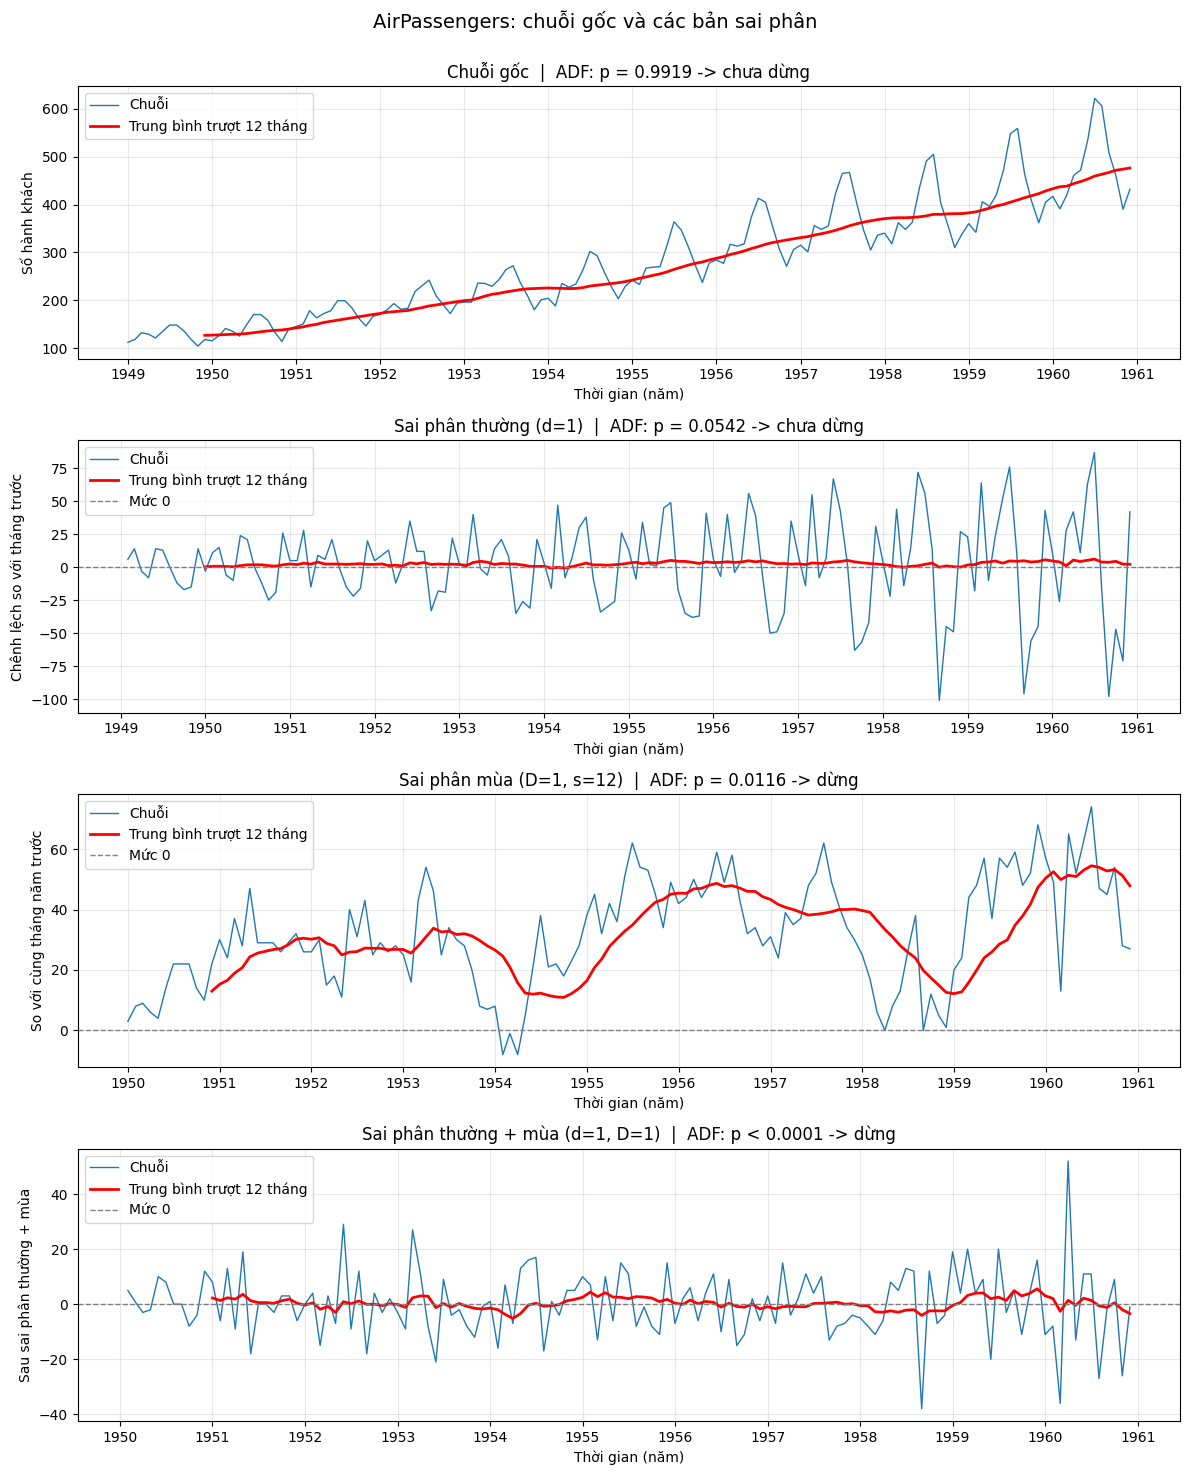

In [31]:
import matplotlib.dates as mdates

def p_adf(x):
    return adfuller(x.dropna(), regression="c", autolag="AIC", result_object=False)[1]

def fmt_p(p):
    return "p < 0.0001" if p < 0.0001 else f"p = {p:.4f}"

cac_chuoi = [
    (ap,     "Chuỗi gốc",                            "Số hành khách"),
    (d1,     "Sai phân thường (d=1)",                "Chênh lệch so với tháng trước"),
    (s12,    "Sai phân mùa (D=1, s=12)",             "So với cùng tháng năm trước"),
    (d1_s12, "Sai phân thường + mùa (d=1, D=1)",     "Sau sai phân thường + mùa"),
]

fig, axes = plt.subplots(4, 1, figsize=(12, 15))   # bỏ sharex để mỗi đồ thị đều có nhãn năm
for i, (ax, (x, ten, ylab)) in enumerate(zip(axes, cac_chuoi)):
    x = x.dropna()
    p = p_adf(x)
    kq = "dừng" if p <= 0.05 else "chưa dừng"

    ax.plot(x, lw=1, label="Chuỗi")
    ax.plot(x.rolling(12).mean(), color="red", lw=2, label="Trung bình trượt 12 tháng")
    if i > 0:                                        # các bản sai phân: vẽ đường mức 0
        ax.axhline(0, color="gray", ls="--", lw=1, label="Mức 0")

    ax.set_title(f"{ten}  |  ADF: {fmt_p(p)} -> {kq}")
    ax.set_xlabel("Thời gian (năm)")
    ax.set_ylabel(ylab)
    ax.xaxis.set_major_locator(mdates.YearLocator(1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.grid(alpha=0.3)
    ax.legend(loc="upper left")

fig.suptitle("AirPassengers: chuỗi gốc và các bản sai phân", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

**Nhận xét từng đồ thị:**
1. **Chuỗi gốc:** có xu hướng tăng và dao động theo mùa ngày càng lớn; đường đỏ đi lên liên tục → không dừng.
2. **Sai phân thường (d = 1):** xu hướng đã mất (đường đỏ gần mức 0) nhưng dao động theo mùa vẫn còn và phình ra về cuối; ADF p = 0.0542 sát ngưỡng nên chưa kết luận dừng.
3. **Sai phân mùa (D = 1):** mẫu mùa giảm, ADF cho dừng (p = 0.0116) nhưng đường đỏ **vẫn trôi lên xuống**, tức kỳ vọng chưa thật ổn định. ADF và quan sát bằng mắt không hoàn toàn trùng nhau.
4. **Sai phân thường + mùa (d = 1, D = 1):** đường đỏ nằm ngang quanh 0 và p < 0.0001 → dừng.

## 7. Phân tích mùa vụ: vì sao s = 12 và D = 1?

Phần này làm ba việc:
1. **Chứng minh có mùa vụ** bằng số liệu: mỗi tháng có mức cao hay thấp đặc trưng, lặp lại hằng năm.
2. **Tính tay một giá trị sai phân mùa** để hiểu `diff(12)` làm gì.
3. **Thử các chu kỳ s khác nhau** để xem vì sao chọn s = 12.

### 7.1. Mẫu mùa vụ theo tháng

Để thấy mùa vụ, ta tính **độ lệch của mỗi tháng so với trung bình của chính năm đó** (cách này loại bớt ảnh hưởng của xu hướng tăng), rồi lấy trung bình theo tháng trên 12 năm.
- Cột **dương**: tháng đó thường cao hơn mức trung bình năm.
- Cột **âm**: tháng đó thường thấp hơn.
- Nếu không có mùa vụ, các cột sẽ xấp xỉ 0.

T1    -38.5
T2    -45.3
T3    -10.1
T4    -13.2
T5     -8.5
T6     31.4
T7     71.0
T8     70.8
T9     22.1
T10   -13.7
T11   -47.5
T12   -18.5
Name: Passengers, dtype: float64


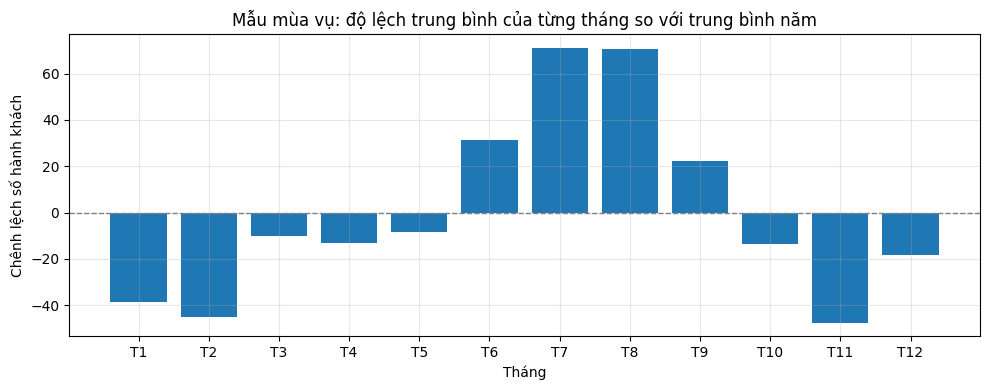

In [32]:
thang = ["T1", "T2", "T3", "T4", "T5", "T6", "T7", "T8", "T9", "T10", "T11", "T12"]

lech = ap - ap.groupby(ap.index.year).transform("mean")   # độ lệch so với trung bình của chính năm đó
mua = lech.groupby(lech.index.month).mean()
mua.index = thang
print(mua.round(1))

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(mua.index, mua.values)
ax.axhline(0, color="gray", ls="--", lw=1)
ax.set_title("Mẫu mùa vụ: độ lệch trung bình của từng tháng so với trung bình năm")
ax.set_xlabel("Tháng")
ax.set_ylabel("Chênh lệch số hành khách")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Nhận xét:**
- Các tháng **T7 và T8** có cột dương cao nhất (khoảng +70 hành khách so với trung bình năm), tiếp theo là T6 và T9. Các tháng **T11 và T2** có cột âm sâu nhất (khoảng −47 và −45).
- Mùa cao điểm rơi vào mùa hè (T6 đến T9), mùa thấp điểm rơi vào đầu năm và cuối năm.
- Các cột lệch xa mức 0 → **có mùa vụ rõ rệt**. Mẫu này lặp lại mỗi năm, tức chu kỳ **12 tháng**.

### 7.2. Tính tay một giá trị sai phân mùa

Sai phân mùa tại tháng 1/1950 = (số hành khách tháng 1/1950) − (số hành khách tháng 1/1949), tức **trừ đi cùng tháng năm trước**. Ta kiểm tra bằng code xem tính tay có trùng với `diff(12)` không.

In [33]:
t1 = pd.Timestamp("1950-01-01")
t0 = pd.Timestamp("1949-01-01")

print("Tháng 1/1950 =", ap[t1], "| Tháng 1/1949 =", ap[t0])
print("Tính tay      :", ap[t1] - ap[t0])
print("diff(12) (s12):", s12[t1])

Tháng 1/1950 = 115 | Tháng 1/1949 = 112
Tính tay      : 3
diff(12) (s12): 3.0


### 7.3. Vì sao chọn s = 12? Thử các chu kỳ khác

Nếu chọn đúng chu kỳ mùa, sai phân mùa sẽ **loại được mẫu lặp**, nên chuỗi còn lại **dao động ít hơn** (độ lệch chuẩn nhỏ). Ta thử nhiều giá trị s sau khi đã sai phân thường (d = 1) và so sánh độ lệch chuẩn.

In [34]:
print("Độ lệch chuẩn của chuỗi sau sai phân thường + sai phân mùa với từng s:")
for s in [4, 6, 9, 11, 12, 13]:
    x = ap.diff().diff(s).dropna()
    print(f"s = {s:>2}: số điểm = {len(x):>3} | std = {x.std():.2f}")

Độ lệch chuẩn của chuỗi sau sai phân thường + sai phân mùa với từng s:
s =  4: số điểm = 139 | std = 53.89
s =  6: số điểm = 137 | std = 48.61
s =  9: số điểm = 134 | std = 51.46
s = 11: số điểm = 132 | std = 38.75
s = 12: số điểm = 131 | std = 12.36
s = 13: số điểm = 130 | std = 38.81


**Nhận xét:**
- Độ lệch chuẩn nhỏ nhất ở **s = 12** (std = 12.36). Các giá trị khác đều lớn hơn nhiều: s = 11 và s = 13 khoảng 38.8 (gấp khoảng 3 lần), s = 4, 6, 9 khoảng 49 đến 54 (gấp hơn 4 lần).
- Điều này khớp với chu kỳ 12 tháng quan sát ở mục 7.1: chỉ khi trừ đúng cùng tháng năm trước (cách 12 tháng) thì mẫu mùa mới được loại bỏ. Lệch một tháng (s = 11 hoặc 13) thì mẫu mùa vẫn còn dư nên std lớn.
- Vì vậy chọn **s = 12**.

**Thứ tự sai phân có quan trọng không?** Kiểm tra bên dưới.

In [35]:
a = ap.diff().diff(12).dropna()      # sai phân thường rồi mùa
b = ap.diff(12).diff().dropna()      # sai phân mùa rồi thường
print("Hai thứ tự cho cùng kết quả:", np.allclose(a, b))

Hai thứ tự cho cùng kết quả: True


## 8. Kết luận

- **Có mùa vụ chu kỳ 12 tháng:** mẫu theo tháng ở mục 7.1 lặp lại hằng năm, và s = 12 cho độ dao động nhỏ nhất ở mục 7.3.
- **Chọn d = 1 và D = 1 (s = 12)** cho SARIMA. Lý do: d = 1 một mình chưa chắc dừng (p = 0.0542); D = 1 một mình ADF cho dừng nhưng kỳ vọng còn trôi; kết hợp cả hai cho chuỗi dừng rõ ràng và ổn định.
- Thứ tự áp dụng d và D không ảnh hưởng kết quả.
- Chuỗi `d1_s12` (131 điểm) là đầu vào cho **bước 4** (ACF/PACF để xác định p, q, P, Q).

**Hạn chế:** ở đồ thị cuối, dao động về cuối chuỗi (1958 đến 1960) lớn hơn đầu chuỗi nên phương sai chưa thật đều. Nếu nhóm thống nhất, có thể lấy log trước khi sai phân.